# Modèle 3 — Isolation Forest : « cette charge est bizarre »

**Membre 4 — Gatsoundou Junior Stevy** · Étape 6 du pipeline (modèle 3), étape 7 (MLflow)

## Méthode de travail de ce notebook

Chaque étape suit toujours le même déroulé. **On raisonne avant de voir les résultats.**

| # | Bloc | Contenu |
|---|---|---|
| 1 | **Objectif** | Ce qu'on veut savoir ou produire à cette étape |
| 2 | **Principe de data science** | L'idée qu'on mobilise, les alternatives, et pourquoi ce choix convient à **notre** problème |
| 3 | **Hypothèses** (au moins 3) | Écrites **avant** d'exécuter : ce qu'on s'attend à voir et comment on le vérifie |
| 4 | **Code** | Chaque hypothèse est testée explicitement → `CONFIRMÉE ✅` ou `RÉFUTÉE ❌` |
| 5 | **Vérification** | Ce qui est confirmé, ce qui est réfuté, et la **correction** si on s'est trompé |

Une hypothèse réfutée n'est pas un échec : c'est une information qui change la suite du travail.

## Le problème

- **31 035 sessions de charge** de 20 véhicules BAIC EU500 (2019 → 2021), une ligne par session (`sessions_features.parquet`, étape 5).
- **Aucune étiquette de panne** : on ne sait pas quelles sessions sont réellement défaillantes.
- **Deux anomalies** à détecter : la **surchauffe** (température) et la **cellule défaillante** (écart de tension entre cellules).
- Les **seuils** (45/48 °C, 60/100 mV) ne voient que les valeurs extrêmes qu'on connaît déjà.

**Rôle du modèle 3 :** repérer les sessions qui **ne ressemblent pas aux autres**, y compris sous les seuils ou par une *combinaison* inhabituelle (ex. température normale mais montée très rapide), **sans qu'on lui dise ce qu'est une panne**. C'est un problème de **détection d'anomalies non supervisée**.

Sa sortie : un **vote 0/1 par session** (`vote_isolation_forest`), qui entre dans la fusion de Mohamed (4 votes pour la surchauffe, 3 pour la cellule).

## Pourquoi Isolation Forest ? (choix de la méthode)

Pas d'étiquettes → méthodes supervisées impossibles. On compare les méthodes non supervisées classiques :

| Méthode | Principe | Pour notre problème |
|---|---|---|
| **Isolation Forest** | Coupe les données au hasard ; une anomalie est **isolée en peu de coupures** | ✅ sans étiquettes · ✅ rapide sur 31 000 lignes · ✅ aucune hypothèse sur la forme des données · ✅ score interprétable (« facile à isoler ») |
| One-Class SVM | Trace une frontière autour des données normales | ❌ coût ≈ n² (31 000 lignes) · ❌ très sensible au choix du noyau et de la normalisation |
| LOF (Local Outlier Factor) | Compare la densité d'un point à celle de ses voisins | ⚠️ basé sur des distances → normalisation obligatoire · choix du nombre de voisins · plus lent |
| Autoencodeur | Erreur de reconstruction d'un réseau de neurones | ❌ surdimensionné pour 4 à 10 colonnes · ❌ peu explicable devant un jury |
| z-score par colonne | Distance à la moyenne, colonne par colonne | ❌ ne voit pas les combinaisons · déjà couvert par l'approche « seuils » |

**Ce qu'on retient pour la suite :** Isolation Forest tire **au hasard la colonne** de chaque coupure. Le choix des colonnes (étape 2) est donc décisif : une colonne inutile « dilue » les coupures utiles.

## Plan du notebook

| Étape | Contenu | Statut |
|---|---|---|
| **1** | **Données et exploration des features** | ✅ validée (26/11/2026) |
| 2 | Choix des features et de `contamination` | ✅ validée (27/11/2026) |
| 3 | Évaluation par anomalies injectées (+8 °C, +60 mV) | à venir |
| 4 | Contrôle métier : le véhicule 9 ressort-il ? | à venir |
| 5 | Écriture des votes et suivi MLflow | à venir |

---
# Étape 1 — Données et exploration des features

## 1.0 Préparation

**Objectif :** charger les bibliothèques et les paramètres **communs à l'équipe**.

**Principe — reproductibilité :** les chemins, seuils, véhicules de test et la graine aléatoire viennent de `src/config.py`, la **source unique** du projet. Si on les recopiait ici, un changement décidé en équipe (ex. un seuil) ne serait pas répercuté, et nos résultats ne seraient plus comparables à ceux d'Ivan Jr et de Mohamed.

| Bibliothèque | Rôle ici |
|---|---|
| `pandas`, `numpy` | Tableau des sessions, calculs |
| `matplotlib` | Graphiques (enregistrés dans `reports/figures/` pour le rapport) |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)

# Rendre src/ importable, que le notebook soit lancé depuis la racine ou depuis notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import (SESSIONS_PARQUET, FIGURES_DIR, TEST_VEHICLES, RANDOM_STATE,
                        TEMP_ALERTE, TEMP_CRITIQUE, ECART_TENSION_MAX)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Option D (DECISION_SEUIL_CELLULE.md) : alerte cellule à 60 mV.
# Pas encore dans config.py (Mohamed doit ajouter ECART_TENSION_ALERTE) -> défini ici en attendant.
ECART_TENSION_ALERTE = 0.060   # V
ECART_TENSION_CRITIQUE = ECART_TENSION_MAX   # 0,1 V

# Les 4 features candidates : celles qui décrivent directement les deux anomalies.
# Ce choix sera remis en question à l'étape 2 (comparaison avec toutes les features).
FEATURES = ["temp_max", "vitesse_temp", "ecart_v_moyen", "ecart_v_max"]

bilan = {}   # résultat de chaque hypothèse, récapitulé en fin d'étape

def verifier(code_hyp, condition, detail=""):
    # Affiche et enregistre le verdict d'une hypothèse.
    ok = bool(condition)
    bilan[code_hyp] = ok
    print(f"{code_hyp} : {'CONFIRMÉE ✅' if ok else 'RÉFUTÉE ❌'}   {detail}")

print("Sessions         :", SESSIONS_PARQUET)
print("Véhicules test   :", TEST_VEHICLES)
print("Seuils surchauffe:", TEMP_ALERTE, "/", TEMP_CRITIQUE, "°C")
print("Seuils cellule   :", ECART_TENSION_ALERTE, "/", ECART_TENSION_CRITIQUE, "V")

Sessions         : C:\Users\pc\Downloads\DETECTION-ANOMALIE-BATTERIE\data\processed\sessions_features.parquet
Véhicules test   : [17, 18, 19, 20]
Seuils surchauffe: 45 / 48 °C
Seuils cellule   : 0.06 / 0.1 V


## 1.1 Charger les sessions et séparer entraînement / test **par véhicule**

**Objectif :** charger les sessions, vérifier qu'elles respectent le contrat de Kevin, et constituer les jeux d'entraînement (16 véhicules) et de test (4 véhicules : 17, 18, 19, 20).

**Principe — éviter la fuite de données (*data leakage*) :** les sessions d'un même véhicule se ressemblent (même batterie, même conducteur, même climat). Avec une séparation **aléatoire** des sessions, des sessions « sœurs » se retrouveraient des deux côtés : le modèle serait testé sur des véhicules qu'il connaît déjà, et le score serait **trop optimiste**.

| Séparation | Ce qu'elle simule | Pour nous |
|---|---|---|
| Aléatoire par session | — | ❌ fuite : des sessions du même véhicule dans train et test |
| **Par véhicule** (16 / 4) | Un **nouveau véhicule** arrive dans la flotte | ✅ **retenue** (règle commune du projet, `config.TEST_VEHICLES`) |
| Temporelle (2019-20 / 2021) | Le futur de la même flotte | ✅ utile pour la **dérive** → réservée au monitoring Evidently (étape 9) |
| Validation croisée par groupes (`GroupKFold`) | Plusieurs découpages par véhicule | ⚠️ plus robuste, mais demande une métrique ; à envisager à l'étape 3 si les résultats varient beaucoup |

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H1.1** | Le fichier respecte le contrat : 22 colonnes, et `session_id` est **unique** (une ligne = une session) | Liste des colonnes, comptage des doublons | Mohamed joint les votes sur `session_id` → il faudrait joindre sur (`vehicle_id`, `session_id`) et prévenir l'équipe |
| **H1.2** | Les 4 véhicules de test représentent **≈ 20 %** des sessions (entre 15 et 25 %) | Part des sessions de test | Test trop petit (résultats instables) ou trop grand (moins de données d'apprentissage) |
| **H1.3** | Les véhicules de test **ressemblent** à ceux d'entraînement : médiane de chaque feature à ±10 % de celle du train | Comparaison des médianes train / test | Décalage de distribution : le modèle jugerait « atypique » un véhicule seulement parce qu'il est différent |

In [2]:
sessions = pd.read_parquet(SESSIONS_PARQUET)
est_test = sessions["vehicle_id"].isin(TEST_VEHICLES)
train, test = sessions[~est_test], sessions[est_test]

print(f"{len(sessions):,} sessions · {sessions['vehicle_id'].nunique()} véhicules · {sessions.shape[1]} colonnes")
print(f"Train : {len(train):,} sessions ({train['vehicle_id'].nunique()} véhicules)")
print(f"Test  : {len(test):,} sessions ({test['vehicle_id'].nunique()} véhicules : {sorted(int(v) for v in test['vehicle_id'].unique())})")
print()

# H1.1 — contrat
nb_doublons = sessions["session_id"].duplicated().sum()
verifier("H1.1", sessions.shape[1] == 22 and nb_doublons == 0,
         f"{sessions.shape[1]} colonnes, {nb_doublons} session_id en double")

# H1.2 — taille du test
part_test = len(test) / len(sessions)
verifier("H1.2", 0.15 <= part_test <= 0.25, f"part du test = {part_test:.1%}")

# H1.3 — ressemblance train / test
comparaison = pd.DataFrame({"médiane train": train[FEATURES].median(),
                            "médiane test": test[FEATURES].median()})
comparaison["écart relatif"] = comparaison["médiane test"] / comparaison["médiane train"] - 1
display(comparaison)
verifier("H1.3", (comparaison["écart relatif"].abs() <= 0.10).all(),
         "écart max = " + f"{comparaison['écart relatif'].abs().max():.1%}")

31,035 sessions · 20 véhicules · 22 colonnes
Train : 24,817 sessions (16 véhicules)
Test  : 6,218 sessions (4 véhicules : [17, 18, 19, 20])

H1.1 : CONFIRMÉE ✅   22 colonnes, 0 session_id en double
H1.2 : CONFIRMÉE ✅   part du test = 20.0%


,médiane train,médiane test,écart relatif
temp_max,36.0000,36.0000,0.0000
vitesse_temp,0.0517,0.0527,0.0195
ecart_v_moyen,0.0332,0.0339,0.0219
ecart_v_max,0.0410,0.0420,0.0244


H1.3 : CONFIRMÉE ✅   écart max = 2.4%


In [3]:
# Nombre de sessions par véhicule (contexte pour H1.2)
par_vehicule = sessions.groupby("vehicle_id").size().rename("sessions").to_frame()
par_vehicule["jeu"] = np.where(par_vehicule.index.isin(TEST_VEHICLES), "test", "train")
display(par_vehicule.T)

vehicle_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
sessions,1620,1650,1544,1624,1611,1571,1591,1570,1509,1384,1554,1579,1539,1552,1318,1601,1462,1643,1543,1570
jeu,train,train,train,train,train,train,train,train,train,train,train,train,train,train,train,train,test,test,test,test


### Vérification 1.1

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H1.1 | 22 colonnes, `session_id` unique | 22 colonnes, 0 doublon | ✅ | Mohamed peut joindre les votes sur `session_id` |
| H1.2 | test ≈ 20 % | 20,0 % (6 218 sessions sur 31 035) | ✅ | — |
| H1.3 | médianes à ±10 % | écart max 2,4 % (`ecart_v_max`) | ✅ | pas de décalage de distribution **global** (mais voir H1.13 : le véhicule 18 se distingue) |

## 1.2 Qualité des 4 features candidates

**Objectif :** savoir exactement ce que contiennent les colonnes **avant** de modéliser : unités, valeurs manquantes, valeurs infinies, incohérences.

**Principe — « *garbage in, garbage out* »** : un modèle ne vaut que ce que valent ses données. De plus, Isolation Forest de scikit-learn **refuse** les valeurs manquantes et infinies : il faut décider d'un traitement, et ce traitement doit convenir à notre problème.

| Traitement des manquants | Pour nous |
|---|---|
| Supprimer les sessions | ❌ ces sessions n'auraient **pas de vote**, or la fusion de Mohamed attend un vote par session |
| Imputer par la **moyenne** | ❌ la moyenne est tirée par les valeurs extrêmes… c'est-à-dire précisément les anomalies qu'on cherche |
| Imputer par la **médiane** | ✅ **choix provisoire** : robuste aux valeurs extrêmes, simple, et apprise sur le train seulement |
| Imputer par un modèle (KNN) | ⚠️ surdimensionné si les manquants sont rares |

Le choix sera confirmé selon la **quantité** de manquants trouvée ici.

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H1.4** | Les écarts de tension sont en **volts** (pas en mV) : médiane de `ecart_v_max` entre 0,01 et 0,1 | Médiane | Tous les seuils et l'injection (+0,060) seraient faux d'un facteur 1 000 |
| **H1.5** | `vitesse_temp` contient des **valeurs infinies ou manquantes** (sessions de durée nulle → division par 0), mais sur **moins de 1 %** des sessions | Comptage des `inf` et `NaN` | Si > 1 % : l'imputation par la médiane changerait trop de sessions → revoir le calcul de la vitesse avec Kevin |
| **H1.6** | Les données sont **cohérentes** : aucun manquant sur `temp_max` et les écarts (nettoyage de Kevin), `ecart_v_moyen ≤ ecart_v_max` partout (une moyenne ne dépasse pas un maximum), et `temp_max` physiquement plausible (−30 à 60 °C) | Comptages | Erreur dans `sessions.py` à signaler à Kevin |

In [4]:
X = sessions[FEATURES].astype(float)

qualite = pd.DataFrame({
    "manquants": X.isna().sum(),
    "infinis": np.isinf(X).sum(),
    "min": X.replace([np.inf, -np.inf], np.nan).min(),
    "médiane": X.median(),
    "max": X.replace([np.inf, -np.inf], np.nan).max(),
})
qualite["% invalides"] = (qualite["manquants"] + qualite["infinis"]) / len(X)
display(qualite)

# H1.4 — unité des écarts
med = X["ecart_v_max"].median()
verifier("H1.4", 0.01 <= med <= 0.1, f"médiane ecart_v_max = {med:.4f} → {'volts' if med < 1 else 'mV ?'}")

# H1.5 — vitesse_temp
inval = qualite.loc["vitesse_temp", "% invalides"]
verifier("H1.5", 0 < inval < 0.01,
         f"{int(qualite.loc['vitesse_temp', 'manquants'])} NaN + {int(qualite.loc['vitesse_temp', 'infinis'])} inf = {inval:.2%}")

# H1.6 — cohérence
manq = int(X[["temp_max", "ecart_v_moyen", "ecart_v_max"]].isna().sum().sum())
incoherent = int((X["ecart_v_moyen"] > X["ecart_v_max"] + 1e-9).sum())
hors_plage = int((~X["temp_max"].between(-30, 60)).sum())
verifier("H1.6", manq == 0 and incoherent == 0 and hors_plage == 0,
         f"{manq} manquants · {incoherent} sessions moyen > max · {hors_plage} temp_max hors [-30, 60]")

,manquants,infinis,min,médiane,max,% invalides
temp_max,0,0,0.000,36.0000,49.0000,0.0000
vitesse_temp,39,0,0.000,0.0519,1.5000,0.0013
ecart_v_moyen,0,0,0.006,0.0333,0.0767,0.0000
ecart_v_max,0,0,0.006,0.0410,0.0980,0.0000


H1.4 : CONFIRMÉE ✅   médiane ecart_v_max = 0.0410 → volts
H1.5 : CONFIRMÉE ✅   39 NaN + 0 inf = 0.13%
H1.6 : CONFIRMÉE ✅   0 manquants · 0 sessions moyen > max · 0 temp_max hors [-30, 60]


### Vérification 1.2

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H1.4 | écarts en volts | médiane `ecart_v_max` = 0,041 V | ✅ | l'injection +0,060 (= +60 mV) est à la bonne échelle |
| H1.5 | `vitesse_temp` invalide sur 0 à 1 % | 39 NaN, 0 inf (0,13 %) | ✅ | — |
| H1.6 | aucune incohérence | 0 manquant, 0 moyen > max, 0 hors plage | ✅ | mais une session à `temp_max` = 0 °C passe le test → examinée en 1.5 (H1.16) |

**Décision sur les manquants :** ✅ **imputation par la médiane** (apprise sur le train) : elle ne concerne que 39 sessions, et chaque session garde un vote.

## 1.3 Distributions et position des seuils

**Objectif :** voir la **forme** de chaque distribution et où tombent les seuils, pour anticiper le comportement du modèle.

**Principes mobilisés :**

1. **Une anomalie vit dans la queue de la distribution.** Isolation Forest isole facilement les points des queues : plus une queue est longue et isolée, plus ses sessions seront signalées.
2. **`contamination`** (paramètre clé de l'étape 2) = la part de sessions que le modèle déclarera atypiques. Sans étiquettes, on l'**estime** à partir de ce que les seuils trouvent : les mesures de cette étape serviront à la fixer.
3. **Redondance des colonnes :** Isolation Forest choisit une colonne au hasard à chaque coupure. Deux colonnes très corrélées portent **le même signal deux fois** → ce signal sera coupé deux fois plus souvent.
4. **Corrélation de Spearman plutôt que Pearson :** Spearman travaille sur les rangs → elle mesure toute relation *monotone* et n'est pas faussée par les valeurs extrêmes, nombreuses ici.
5. **Échelle logarithmique** sur l'axe des effectifs : sans elle, les quelques sessions anormales (≈ 1 %) seraient invisibles à côté des milliers de sessions normales.

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H1.7** | **Environ 1 %** des sessions dépassent 45 °C (entre 0,5 et 2 %), et **moins de 0,5 %** atteignent 48 °C | Proportions | La `contamination` estimée à partir des seuils change |
| **H1.8** | Les écarts de tension ont une **queue à droite** (asymétrie > 1) et **moins de 1 %** des sessions dépassent 60 mV | Coefficient d'asymétrie (*skewness*), proportion | Si la distribution est symétrique, l'anomalie cellule n'est pas « rare et isolée » → Isolation Forest y sera peu adapté |
| **H1.9** | `ecart_v_moyen` et `ecart_v_max` sont **fortement corrélés** (Spearman > 0,8) | Matrice de corrélation | Si confirmée : le signal cellule compte double parmi les 4 features → à discuter à l'étape 2 (en garder une seule ?) |

In [5]:
Xv = X.replace([np.inf, -np.inf], np.nan)

# H1.7 — surchauffe
p45 = (Xv["temp_max"] > TEMP_ALERTE).mean()
p48 = (Xv["temp_max"] >= TEMP_CRITIQUE).mean()
verifier("H1.7", 0.005 <= p45 <= 0.02 and p48 < 0.005,
         f"> {TEMP_ALERTE} °C : {p45:.2%} · ≥ {TEMP_CRITIQUE} °C : {p48:.2%}")

# H1.8 — queue à droite des écarts
asym = Xv[["ecart_v_moyen", "ecart_v_max"]].skew()
p60 = (Xv["ecart_v_max"] > ECART_TENSION_ALERTE).mean()
verifier("H1.8", (asym > 1).all() and p60 < 0.01,
         f"asymétrie moyen = {asym['ecart_v_moyen']:.2f}, max = {asym['ecart_v_max']:.2f} · > 60 mV : {p60:.2%}")

# H1.9 — redondance
corr = Xv.corr(method="spearman")
display(corr.round(2))
rho = corr.loc["ecart_v_moyen", "ecart_v_max"]
verifier("H1.9", rho > 0.8, f"Spearman(ecart_v_moyen, ecart_v_max) = {rho:.2f}")

# Percentiles utiles pour l'étape 2 (choix de contamination)
display(Xv.quantile([0.5, 0.9, 0.98, 0.99, 0.999]).rename_axis("percentile"))

H1.7 : CONFIRMÉE ✅   > 45 °C : 0.98% · ≥ 48 °C : 0.12%
H1.8 : RÉFUTÉE ❌   asymétrie moyen = -0.54, max = -0.13 · > 60 mV : 0.62%


,temp_max,vitesse_temp,ecart_v_moyen,ecart_v_max
temp_max,1.00,-0.00,0.10,0.14
vitesse_temp,-0.00,1.00,0.36,0.40
ecart_v_moyen,0.10,0.36,1.00,0.91
ecart_v_max,0.14,0.40,0.91,1.00


H1.9 : CONFIRMÉE ✅   Spearman(ecart_v_moyen, ecart_v_max) = 0.91


,temp_max,vitesse_temp,ecart_v_moyen,ecart_v_max
percentile,,,,
0.500,36.0,0.0519,0.0333,0.041
0.900,42.0,0.0858,0.0394,0.049
0.980,45.0,0.1111,0.0426,0.054
0.990,45.0,0.1296,0.0437,0.057
0.999,48.0,0.3146,0.0479,0.073


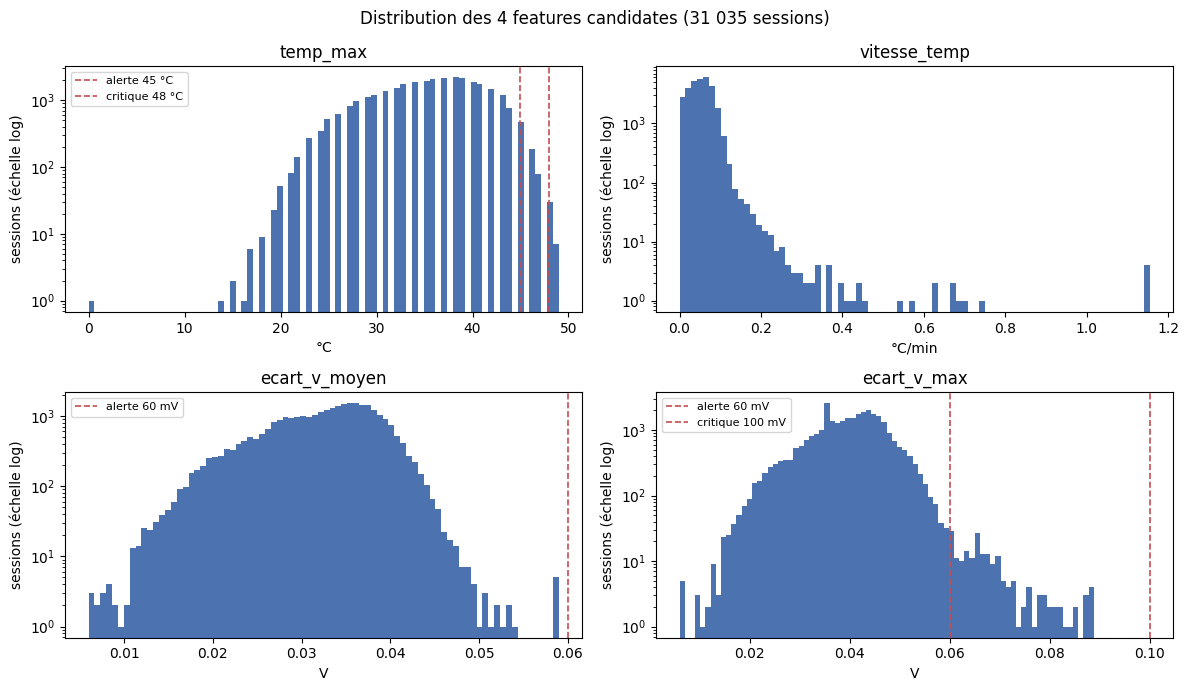

In [6]:
seuils = {
    "temp_max": [(TEMP_ALERTE, "alerte 45 °C"), (TEMP_CRITIQUE, "critique 48 °C")],
    "vitesse_temp": [],
    "ecart_v_moyen": [(ECART_TENSION_ALERTE, "alerte 60 mV")],
    "ecart_v_max": [(ECART_TENSION_ALERTE, "alerte 60 mV"), (ECART_TENSION_CRITIQUE, "critique 100 mV")],
}
unites = {"temp_max": "°C", "vitesse_temp": "°C/min", "ecart_v_moyen": "V", "ecart_v_max": "V"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    valeurs = Xv[col].dropna()
    ax.hist(valeurs.clip(upper=valeurs.quantile(0.9999)), bins=80, color="#4C72B0")
    ax.set_yscale("log")   # sinon les ~1 % d'anomalies sont invisibles
    for valeur, nom in seuils[col]:
        ax.axvline(valeur, color="#C44E52", linestyle="--", linewidth=1.2, label=nom)
    ax.set_title(col)
    ax.set_xlabel(unites[col])
    ax.set_ylabel("sessions (échelle log)")
    if seuils[col]:
        ax.legend(fontsize=8)
fig.suptitle("Distribution des 4 features candidates (31 035 sessions)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "if_distributions.png", dpi=120)
plt.show()

### Vérification 1.3

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H1.7 | ≈ 1 % > 45 °C, < 0,5 % ≥ 48 °C | 0,98 % > 45 °C · 0,12 % ≥ 48 °C | ✅ | — |
| H1.8 | queue à droite (asymétrie > 1), < 1 % > 60 mV | asymétrie **−0,54** (moyen) et **−0,13** (max) · 0,62 % > 60 mV | ❌ | **L'indicateur était mal choisi, pas l'idée** : le graphique montre bien un plateau isolé de 60 à 90 mV sur `ecart_v_max`, mais la queue **gauche** (écarts de 6 à 15 mV) est plus lourde et domine l'asymétrie, qui résume toute la distribution. → on mesure la queue droite seule en 1.5 (H1.8 bis) |
| H1.9 | Spearman > 0,8 | **0,91** | ✅ | le signal cellule compte **double** parmi les 4 features → à trancher à l'étape 2 |

**Observation hors hypothèses :** quelques sessions ont `vitesse_temp` ≈ 1,15 °C/min, très isolées → examinées en 1.5 (H1.15).

**Ce qu'on en tire pour `contamination` (étape 2) :** les seuils signalent ≈ 0,98 % (surchauffe) + 0,62 % (cellule) ≈ **1,6 %** des sessions → une `contamination` de l'ordre de **2 %** est cohérente (à confirmer à l'étape 2).

## 1.4 Comparaison des véhicules

**Objectif :** repérer les véhicules qui se distinguent, en particulier le **véhicule 9**, et vérifier que les véhicules de test ne sont pas des cas extrêmes.

**Principe — validation par la connaissance métier :** sans étiquettes, on ne peut pas calculer une précision. Un moyen de juger un modèle non supervisé est de vérifier qu'il **retrouve ce qu'on sait déjà**. Ici, on sait (`DECISION_SEUIL_CELLULE.md`) que **90 % des sessions au-delà de 60 mV viennent du véhicule 9**. Si les données le confirment, le véhicule 9 devient notre **témoin** : à l'étape 4, le modèle devra le faire ressortir.

**Pourquoi des boxplots :** ils montrent pour chaque véhicule la médiane, la dispersion et les valeurs extrêmes, et permettent de comparer 20 véhicules sur un seul graphique.

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H1.10** | Le véhicule 9 a la **médiane d'`ecart_v_moyen` la plus élevée** des 20 | Classement des médianes | Le véhicule 9 n'est pas un bon témoin « permanent » : son problème ne serait qu'occasionnel |
| **H1.11** | Le véhicule 9 concentre **plus de la moitié** des sessions à `ecart_v_max` > 60 mV | Part du véhicule 9 parmi ces sessions | Le problème de cellule est réparti sur la flotte → le vote cellule ne doit pas être jugé sur le seul véhicule 9 |
| **H1.12** | La température varie **peu d'un véhicule à l'autre** (écart entre médianes de `temp_max` < 5 °C) : la surchauffe dépend plutôt de la saison et du courant que du véhicule | Max − min des médianes | Un véhicule « chaud » en permanence serait signalé en bloc par le modèle |
| **H1.13** | Aucun véhicule de test (17-20) n'est parmi les **3 plus extrêmes** en `ecart_v_moyen` | Rang des véhicules de test | L'évaluation sur le test serait biaisée par un véhicule anormal dans son ensemble |

In [7]:
med_vehicule = Xv.groupby(sessions["vehicle_id"]).median()
rang_ecart = med_vehicule["ecart_v_moyen"].rank(ascending=False).astype(int)

# H1.10 — véhicule 9 en tête
verifier("H1.10", rang_ecart.get(9) == 1,
         f"rang du véhicule 9 = {rang_ecart.get(9)} / 20 · en tête : véhicule {rang_ecart.idxmin()}")

# H1.11 — concentration des sessions > 60 mV
au_dessus = sessions.loc[Xv["ecart_v_max"] > ECART_TENSION_ALERTE, "vehicle_id"]
part_v9 = (au_dessus == 9).mean() if len(au_dessus) else np.nan
verifier("H1.11", part_v9 > 0.5, f"{len(au_dessus)} sessions > 60 mV, dont {part_v9:.0%} du véhicule 9")
display(au_dessus.value_counts().head(5).rename("sessions > 60 mV").to_frame().T)

# H1.12 — homogénéité de la température entre véhicules
etendue = med_vehicule["temp_max"].max() - med_vehicule["temp_max"].min()
verifier("H1.12", etendue < 5, f"médianes temp_max de {med_vehicule['temp_max'].min():.1f} à {med_vehicule['temp_max'].max():.1f} °C (étendue {etendue:.1f} °C)")

# H1.13 — véhicules de test non extrêmes
rangs_test = rang_ecart[rang_ecart.index.isin(TEST_VEHICLES)]
verifier("H1.13", (rangs_test > 3).all(), "rangs des véhicules de test : " + ", ".join(f"#{v} → {r}" for v, r in rangs_test.items()))

H1.10 : RÉFUTÉE ❌   rang du véhicule 9 = 11 / 20 · en tête : véhicule 18
H1.11 : CONFIRMÉE ✅   193 sessions > 60 mV, dont 90% du véhicule 9


vehicle_id,9,13,18,6
sessions > 60 mV,173,11,8,1


H1.12 : CONFIRMÉE ✅   médianes temp_max de 35.0 à 36.0 °C (étendue 1.0 °C)
H1.13 : RÉFUTÉE ❌   rangs des véhicules de test : #17 → 5, #18 → 1, #19 → 10, #20 → 18


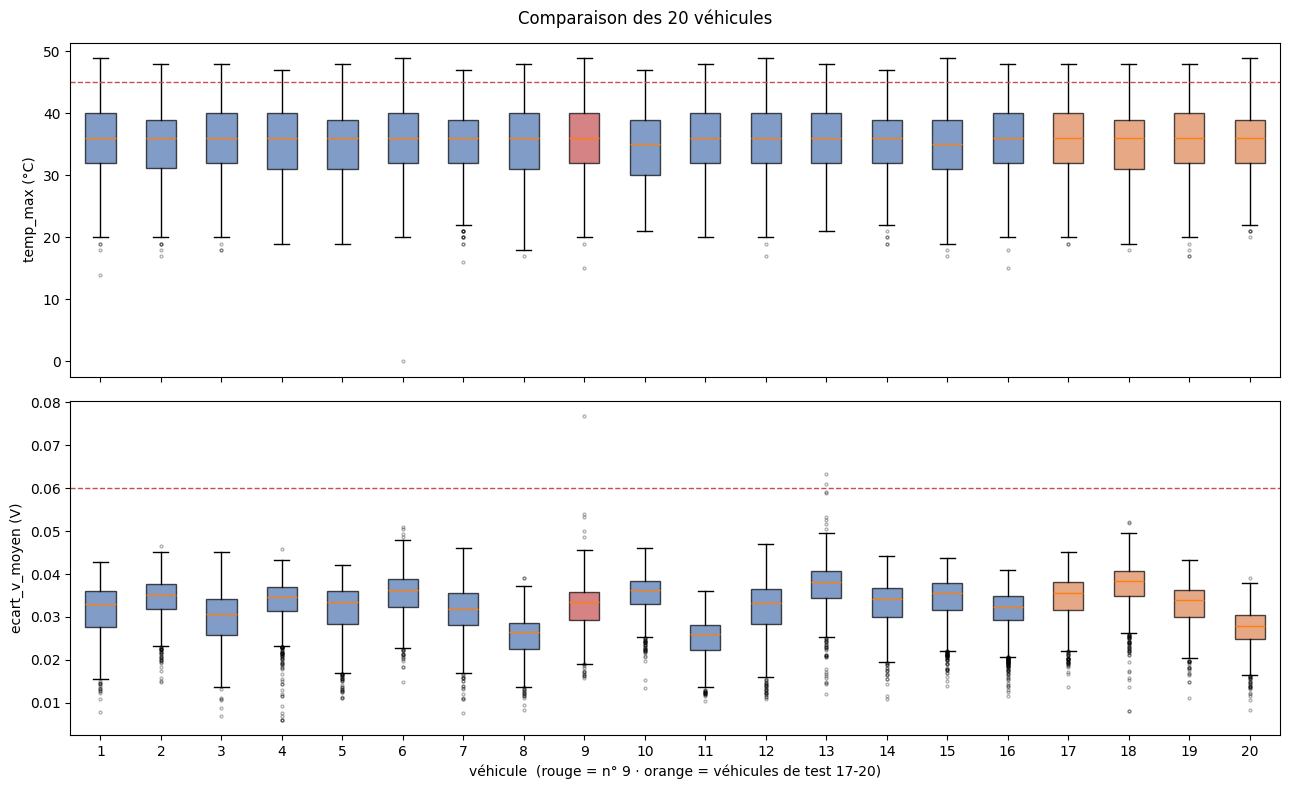

In [8]:
vehicules = sorted(sessions["vehicle_id"].unique())
couleurs = ["#C44E52" if v == 9 else "#DD8452" if v in TEST_VEHICLES else "#4C72B0" for v in vehicules]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, col, seuil in [(axes[0], "temp_max", TEMP_ALERTE), (axes[1], "ecart_v_moyen", ECART_TENSION_ALERTE)]:
    donnees = [Xv.loc[sessions["vehicle_id"] == v, col].dropna() for v in vehicules]
    boites = ax.boxplot(donnees, patch_artist=True, showfliers=True,
                        flierprops={"markersize": 2, "alpha": 0.3})
    for boite, couleur in zip(boites["boxes"], couleurs):
        boite.set_facecolor(couleur)
        boite.set_alpha(0.7)
    ax.axhline(seuil, color="#C44E52", linestyle="--", linewidth=1)
    ax.set_ylabel(f"{col} ({unites[col]})")
axes[1].set_xticks(range(1, len(vehicules) + 1), vehicules)
axes[1].set_xlabel("véhicule  (rouge = n° 9 · orange = véhicules de test 17-20)")
fig.suptitle("Comparaison des 20 véhicules")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "if_boxplots_vehicules.png", dpi=120)
plt.show()

### Vérification 1.4

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H1.10 | véhicule 9 en tête sur `ecart_v_moyen` | rang **11 / 20** (en tête : véhicule 18) | ❌ | La plupart des sessions du véhicule 9 sont normales : son problème n'est **pas permanent** mais fait de **pics** sur `ecart_v_max`. Dégradation dans le temps ou pics ponctuels ? → testé en 1.5 (H1.14). À noter : sur Zhang on a retenu l'écart **moyen**, or chez BAIC le signal du véhicule 9 est dans l'écart **max** |
| H1.11 | véhicule 9 > 50 % des sessions > 60 mV | 193 sessions, dont **90 %** du véhicule 9 (173) ; puis n° 13 (11), n° 18 (8) | ✅ | le véhicule 9 reste notre **témoin cellule**, à condition de regarder `ecart_v_max` |
| H1.12 | étendue des médianes `temp_max` < 5 °C | 35 à 36 °C (étendue 1 °C) | ✅ | la surchauffe ne dépend pas du véhicule |
| H1.13 | véhicules de test hors du top 3 | n° 18 → **1ᵉʳ**, n° 17 → 5ᵉ, n° 19 → 10ᵉ, n° 20 → 18ᵉ | ❌ | Les écarts entre véhicules sont faibles (médianes de 26 à 38 mV), mais le test contient le véhicule le plus « haut ». On **ne change pas** `TEST_VEHICLES` (règle d'équipe) ; à l'étape 3, on regardera le taux d'atypiques **véhicule par véhicule** pour ne pas confondre « véhicule 18 » et « anomalie » |

## 1.5 Corrections : vérifier ce que les hypothèses réfutées et les observations ont soulevé

**Objectif :** ne pas laisser de question ouverte avant de modéliser. Trois hypothèses ont été réfutées et deux observations sont suspectes ; chacune peut changer les choix de l'étape 2.

**Principes mobilisés :**

1. **Règle de Tukey pour les valeurs extrêmes** (H1.8 bis) : une valeur est « extrême » au-delà de **Q3 + 3 × IQR** (IQR = Q3 − Q1). Contrairement à l'asymétrie, cette mesure ne regarde **qu'un côté** de la distribution et repose sur des quartiles, donc elle n'est pas influencée par les valeurs extrêmes elles-mêmes (robuste). Le facteur 3 (au lieu de 1,5) vise les valeurs *très* extrêmes.
2. **Analyse temporelle** (H1.14) : une anomalie qui se **concentre dans le temps** indique une dégradation (ou un événement) ; une anomalie **dispersée** indique plutôt des conditions de charge ponctuelles. Pour le modèle, cela change tout : une dégradation progressive peut finir par paraître « normale » si on entraîne sur toute la période.
3. **Distinguer artefact et anomalie** (H1.15, H1.16) : une valeur extrême peut venir d'un **calcul** (division par une durée très courte) ou d'un **capteur** défaillant, et non de la batterie. Ces sessions doivent être identifiées, sinon le modèle « gaspille » ses votes sur des erreurs de mesure — que les règles du projet imposent de ne **jamais** compter comme anomalies.

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H1.8 bis** | La queue **droite** d'`ecart_v_max` existe : **plus de 0,1 %** des sessions au-delà de Q3 + 3 × IQR | Règle de Tukey, côté droit seulement | Pas de sessions isolées sur la cellule → Isolation Forest y sera peu utile |
| **H1.14** | Les sessions du véhicule 9 au-delà de 60 mV sont **concentrées dans le temps** : plus de 70 % sur une seule période de 6 mois | Répartition par semestre + graphique dans le temps | Pics dispersés → on compare leurs conditions de charge (SOC, courant) aux autres sessions du véhicule 9 |
| **H1.15** | Les sessions à `vitesse_temp` > 1 °C/min sont des **artefacts** : elles durent toutes **moins de 10 minutes** | Durée de ces sessions | Ce sont de vraies montées rapides → de vraies anomalies, à garder |
| **H1.16** | Les sessions à `temp_max` ≤ 5 °C sont des **erreurs capteur** : `temp_debut` ≤ 5 °C aussi, ou durée < 10 min | Détail de ces sessions | Charge réellement froide (hiver) → valeur légitime |

In [9]:
# H1.8 bis — queue droite (règle de Tukey, facteur 3)
for col in ["ecart_v_max", "ecart_v_moyen"]:
    q1, q3 = Xv[col].quantile([0.25, 0.75])
    borne = q3 + 3 * (q3 - q1)
    part = (Xv[col] > borne).mean()
    print(f"{col:14s} Q1 = {q1:.4f}  Q3 = {q3:.4f}  borne Q3 + 3·IQR = {borne:.4f} V  → {part:.2%} au-delà")
    if col == "ecart_v_max":
        verifier("H1.8 bis", part > 0.001, f"{part:.2%} des sessions dans la queue droite extrême d'ecart_v_max")

ecart_v_max    Q1 = 0.0350  Q3 = 0.0450  borne Q3 + 3·IQR = 0.0750 V  → 0.09% au-delà
H1.8 bis : RÉFUTÉE ❌   0.09% des sessions dans la queue droite extrême d'ecart_v_max
ecart_v_moyen  Q1 = 0.0283  Q3 = 0.0369  borne Q3 + 3·IQR = 0.0625 V  → 0.01% au-delà


In [10]:
# H1.14 — le véhicule 9 dans le temps
v9 = sessions[sessions["vehicle_id"] == 9].sort_values("debut").copy()
v9["semestre"] = v9["debut"].dt.year.astype(str) + "-S" + ((v9["debut"].dt.month - 1) // 6 + 1).astype(str)
v9["haute"] = v9["ecart_v_max"] > ECART_TENSION_ALERTE

repartition = v9.groupby("semestre").agg(sessions=("haute", "size"), au_dessus_60mV=("haute", "sum"))
repartition["part des > 60 mV du véhicule 9"] = repartition["au_dessus_60mV"] / repartition["au_dessus_60mV"].sum()
display(repartition)

part_max = repartition["part des > 60 mV du véhicule 9"].max()
verifier("H1.14", part_max > 0.7,
         f"semestre le plus chargé : {repartition['part des > 60 mV du véhicule 9'].idxmax()} avec {part_max:.0%} des sessions > 60 mV")

# Explication alternative (pics ponctuels) : conditions de charge des sessions hautes vs les autres
display(v9.groupby("haute")[["soc_debut", "courant_moyen", "temp_max", "duree_min"]].median()
          .rename(index={False: "≤ 60 mV", True: "> 60 mV"}))

,sessions,au_dessus_60mV,part des > 60 mV du véhicule 9
semestre,,,
2019-S2,302,0,0.0000
2020-S1,232,0,0.0000
2020-S2,401,12,0.0694
2021-S1,323,68,0.3931
2021-S2,251,93,0.5376


H1.14 : RÉFUTÉE ❌   semestre le plus chargé : 2021-S2 avec 54% des sessions > 60 mV


,soc_debut,courant_moyen,temp_max,duree_min
haute,,,,
≤ 60 mV,37.2,-59.3719,35.0,72.05
> 60 mV,14.0,-64.9513,39.0,83.35


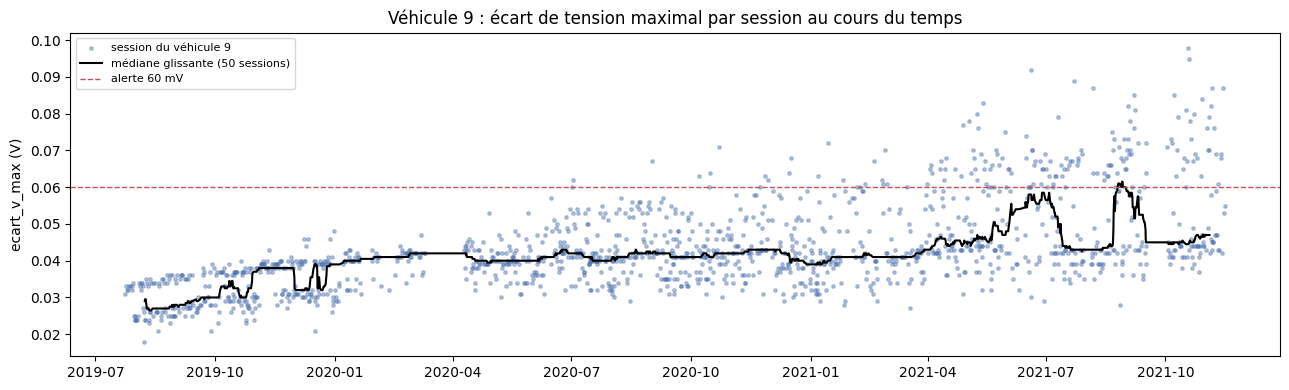

In [11]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.scatter(v9["debut"], v9["ecart_v_max"], s=6, alpha=0.4, color="#4C72B0", label="session du véhicule 9")
ax.plot(v9["debut"], v9["ecart_v_max"].rolling(50, center=True).median(), color="black",
        linewidth=1.5, label="médiane glissante (50 sessions)")
ax.axhline(ECART_TENSION_ALERTE, color="#C44E52", linestyle="--", linewidth=1, label="alerte 60 mV")
ax.set_ylabel("ecart_v_max (V)")
ax.set_title("Véhicule 9 : écart de tension maximal par session au cours du temps")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "if_vehicule9_temps.png", dpi=120)
plt.show()

In [12]:
colonnes_detail = ["vehicle_id", "debut", "duree_min", "nb_mesures", "temp_debut", "temp_max", "vitesse_temp", "soc_debut", "soc_fin"]

# H1.15 — montées de température très rapides
rapides = sessions[Xv["vitesse_temp"] > 1]
display(rapides[colonnes_detail])
verifier("H1.15", len(rapides) > 0 and (rapides["duree_min"] < 10).all(),
         f"{len(rapides)} sessions > 1 °C/min, durée max = {rapides['duree_min'].max():.1f} min")

# H1.16 — températures maximales anormalement basses
froides = sessions[Xv["temp_max"] <= 5]
display(froides[colonnes_detail])
verifier("H1.16", len(froides) > 0 and ((froides["temp_debut"] <= 5) | (froides["duree_min"] < 10)).all(),
         f"{len(froides)} session(s) avec temp_max ≤ 5 °C")

,vehicle_id,debut,duree_min,nb_mesures,temp_debut,temp_max,vitesse_temp,soc_debut,soc_fin
14764,10,2020-05-16 12:50:53,0.8333,6,31,32,1.2000,74.4,74.8
21517,14,2021-04-10 11:45:10,0.8167,7,27,28,1.2245,61.2,61.2
21827,14,2021-10-11 18:44:28,0.6667,6,30,31,1.5000,97.6,98.0
28888,19,2021-01-12 13:08:16,0.6667,5,25,26,1.5000,93.2,93.6


H1.15 : CONFIRMÉE ✅   4 sessions > 1 °C/min, durée max = 0.8 min


,vehicle_id,debut,duree_min,nb_mesures,temp_debut,temp_max,vitesse_temp,soc_debut,soc_fin
9109,6,2021-03-06 16:00:09,0.0,1,0,0,NaN,50.8,50.8


H1.16 : CONFIRMÉE ✅   1 session(s) avec temp_max ≤ 5 °C


### Vérification 1.5

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H1.8 bis | > 0,1 % au-delà de Q3 + 3·IQR | `ecart_v_max` : **0,09 %** au-delà de 75 mV (≈ 28 sessions) · `ecart_v_moyen` : 0,01 % | ❌ (de justesse) | On ne déplace pas le seuil après coup (il était arbitraire). L'anomalie cellule BAIC n'est pas faite de points très éloignés mais d'un **glissement progressif**. L'écart **moyen** n'a presque pas de queue : sur BAIC, c'est l'écart **max** qui porte le signal → si on n'en garde qu'un (H1.9), plutôt `ecart_v_max` |
| H1.14 | > 70 % des sessions > 60 mV du véhicule 9 sur un semestre | 0 → 0 → 12 → 68 → **93** sessions par semestre (2019-S2 → 2021-S2) ; max 54 % sur 2021-S2 | ❌ | L'hypothèse supposait un **événement unique** ; la réalité est une **dégradation progressive** (médiane de 30 mV en 2019 à ≈ 45 mV en 2021, dispersion qui explose en 2021). Les pics apparaissent aussi **à faible charge** : SOC de départ médian **14 %** contre 37 % (à SOC bas, la courbe de tension est plus raide et le déséquilibre entre cellules se voit davantage). → **La cellule du véhicule 9 se dégrade, et le défaut se révèle surtout batterie presque vide** |
| H1.15 | sessions > 1 °C/min toutes < 10 min | 4 sessions, toutes **< 1 min** (5 à 7 mesures) | ✅ | **Artefact de calcul** (+1 °C / 0,7 min = 1,5 °C/min). Plus largement : **350 sessions < 5 min**, 180 sessions < 10 mesures |
| H1.16 | `temp_max` ≤ 5 °C = erreur capteur | 1 session (véhicule 6) : **1 seule mesure**, durée 0, températures à 0 | ✅ | **Enregistrement isolé**, pas une charge → à signaler à Kevin |

---
## Bilan de l'étape 1

In [13]:
recap = pd.Series(bilan).map({True: "CONFIRMÉE ✅", False: "RÉFUTÉE ❌"}).rename("verdict").to_frame()
display(recap)
print(f"{sum(bilan.values())} / {len(bilan)} hypothèses confirmées")

,verdict
H1.1,CONFIRMÉE ✅
H1.2,CONFIRMÉE ✅
H1.3,CONFIRMÉE ✅
H1.4,CONFIRMÉE ✅
H1.5,CONFIRMÉE ✅
H1.6,CONFIRMÉE ✅
H1.7,CONFIRMÉE ✅
H1.8,RÉFUTÉE ❌
H1.9,CONFIRMÉE ✅
H1.10,RÉFUTÉE ❌


12 / 17 hypothèses confirmées


### Conclusions de l'étape 1 (validées par Stevy le 26/11/2026)

| Thème | Conclusion | Hypothèses |
|---|---|---|
| **Données** | Contrat respecté, unités en volts, aucune incohérence ; test = 20 % et semblable au train dans l'ensemble | H1.1 – H1.6 |
| **Artefacts** | Les sessions très courtes (< 5 min, 350 sessions) produisent des valeurs aberrantes de calcul ou de capteur, qui ne sont **pas** des anomalies de batterie | H1.15, H1.16 |
| **Surchauffe** | ≈ 1 % des sessions > 45 °C, sans effet véhicule | H1.7, H1.12 |
| **Cellule** | Signal porté par l'écart **max** (l'écart moyen n'a presque pas de queue chez BAIC) ; les deux écarts sont redondants (ρ = 0,91) | H1.8, H1.8 bis, H1.9 |
| **Véhicule 9** | Dégradation **progressive** de la cellule (de 2020-S2 à 2021-S2), visible surtout à **faible SOC** ; 90 % des sessions > 60 mV | H1.10, H1.11, H1.14 |
| **Véhicules de test** | Le véhicule 18 a les écarts les plus élevés de la flotte (sans dépasser 60 mV en médiane) | H1.13 |

### Décisions pour l'étape 2

| Décision | Justification |
|---|---|
| **Imputation par la médiane** (apprise sur le train) | 39 sessions seulement ; robuste aux extrêmes ; chaque session garde un vote (H1.5) |
| **Exclure de l'entraînement les sessions < 5 min**, mais continuer à les **noter** (vote conservé, marquées « peu fiables ») | Ce sont des artefacts (H1.15, H1.16) : le modèle ne doit pas apprendre que ces valeurs existent. On ne modifie pas `sessions.py` → **à signaler à Kevin** |
| **Comparer « deux écarts » et « `ecart_v_max` seul »** — hypothèse de départ : `ecart_v_max` seul suffit | Redondance (H1.9) et signal porté par le max (H1.8 bis) |
| **Tester `soc_debut` comme contexte** (avec / sans) | Un grand écart à SOC bas est physiquement attendu ; à SOC élevé, il est vraiment suspect (H1.14) |
| **`contamination` ≈ 2 %** comme point de départ | Les seuils signalent ≈ 1,6 % des sessions (H1.7, H1.8) |
| **Étape 3 : taux d'atypiques véhicule par véhicule** dans le test | Ne pas confondre « véhicule 18 » et « anomalie » (H1.13) |
| **Étape 4 : le véhicule 9 doit ressortir surtout en 2021** | Dégradation progressive (H1.14) |
| **Étape 9 (Evidently)** : le véhicule 9 sera l'exemple de dérive 2019-2020 → 2021 | H1.14 |

> ✋ **Point de validation** : l'étape 2 ne commence qu'après validation de ce bilan par Stevy.

---
# Étape 2 — Choix des features et de `contamination`

**Objectif :** choisir **quelles colonnes** on donne au modèle et **quelle part** des sessions il signale.

## Principes de data science mobilisés

**1. Séparer « bien classer » et « où couper » (qualité du score vs point de fonctionnement).**
Isolation Forest donne à chaque session un **score de bizarrerie**. Le paramètre `contamination` ne change **pas** les arbres : il fixe seulement le **seuil** au quantile (1 − `contamination`) des scores d'entraînement. On a donc deux questions indépendantes :

| Question | Mesure | Dépend de `contamination` ? |
|---|---|---|
| Quelles colonnes ? → le score range-t-il les anomalies au-dessus des sessions normales ? | **AUROC** | ❌ non |
| Quel seuil ? → combien d'anomalies attrape-t-on, pour combien de sessions signalées ? | **rappel** à 1, 2, 3 % | ✅ oui |

On entraîne donc **un seul modèle par configuration**, et on applique ensuite les trois seuils nous-mêmes (même calcul que `contamination`, en plus rapide).

**2. Pourquoi l'AUROC ici (et pas la PR-AUC ni l'accuracy) ?** On compare 300 sessions modifiées à **ces mêmes** 300 sessions avant modification : les deux classes sont **équilibrées** (50/50). L'AUROC est alors la bonne mesure : c'est la probabilité qu'une session modifiée ait un score plus élevé que sa version normale (0,5 = hasard, 1 = parfait). La PR-AUC serait nécessaire sur des données déséquilibrées (1 % d'anomalies) — ce n'est pas le cas de ce banc d'essai. L'accuracy est exclue (règle du projet).

**3. Évaluer sans étiquettes : les anomalies injectées.** On prend des sessions **normales selon les seuils** (`temp_max` < 45 °C et `ecart_v_max` ≤ 60 mV) des véhicules de **test**, et on y ajoute une anomalie connue :
- surchauffe : `temp_max` + 8 °C (et `vitesse_temp` recalculée) → une session à 36 °C passe à 44 °C, **sous** le seuil : c'est exactement le cas que les seuils ratent ;
- cellule : `ecart_v_max` + 60 mV.

La **même** base de sessions sert à toutes les configurations → comparaison équitable.
⚠️ **Limite connue :** l'injection touche `temp_max`, `vitesse_temp` et `ecart_v_max`. Elle **favorise** les configurations construites sur ces colonnes. Une anomalie qui ne toucherait que le courant ou la durée ne serait pas vue par les petites configurations. On le dira dans le rapport.

**4. Un modèle aléatoire se juge sur plusieurs graines.** Isolation Forest tire ses coupures au hasard : deux graines donnent deux résultats un peu différents. On entraîne chaque configuration avec **3 graines** et on regarde la moyenne **et l'écart-type**. Une différence plus petite que l'écart-type n'est pas une vraie différence.

**5. Dilution et redondance** (étape 1, H1.9) : chaque coupure se fait sur une colonne tirée au hasard. Ajouter une colonne sans rapport avec les anomalies réduit la part des coupures utiles ; deux colonnes redondantes donnent un poids double au même signal.

**6. Contrôle métier** : le véhicule 9 (dégradation de la cellule, étape 1) doit ressortir dans le classement des véhicules.

## Les configurations comparées

Toutes sont entraînées sur les véhicules d'entraînement, **sans les sessions de moins de 5 minutes** (décision de l'étape 1), avec imputation par la médiane puis normalisation.

| Config | Colonnes | Ce qu'elle teste |
|---|---|---|
| **A** | les 10 features de session complète | référence « tout donner au modèle » |
| **B** | `temp_max`, `vitesse_temp`, `ecart_v_moyen`, `ecart_v_max` | les 4 features actuelles du code |
| **C** | `temp_max`, `vitesse_temp`, `ecart_v_max` | B sans la redondance (H1.9, H1.8 bis) |
| **D** | C + `soc_debut` | le SOC comme contexte de la cellule (H1.14) |

*Note sur la normalisation :* Isolation Forest coupe chaque colonne entre son min et son max, il est donc **insensible à l'échelle** — le `StandardScaler` ne change pas ses résultats. On le garde pour rester conforme au pipeline du projet et pouvoir comparer avec des méthodes à distance (LOF) si besoin.

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H2.1** | **Dilution** : A est nettement moins bonne que B — AUROC moyenne (surchauffe + cellule) inférieure d'**au moins 0,05** | AUROC moyenne sur 3 graines | Les colonnes de contexte aident → garder plus de colonnes |
| **H2.2** | **Redondance inutile** : C fait aussi bien que B — AUROC moyenne à **±0,02** | Différence d'AUROC moyenne | L'écart moyen apporte une information propre → garder les deux écarts |
| **H2.3** | **Le SOC aide la cellule** : D améliore le **rappel cellule à 2 %** d'au moins **5 points** par rapport à C | Rappel cellule à 2 % | Le contexte SOC n'aide pas (ou dilue) → ne pas l'ajouter |
| **H2.4** | **Exclure les sessions < 5 min** de l'entraînement **réduit** la part des votes (à 2 %) qui tombent sur ces sessions | Config C entraînée avec / sans les sessions courtes | Exclure ne suffit pas → il faudra les **écarter du vote** (vote « non évaluable ») à l'étape 5 |
| **H2.5** | **2 % est le bon compromis** : pour la meilleure configuration, le gain de rappel de 2 → 3 % est **plus faible** que celui de 1 → 2 % (rendements décroissants) | Rappel moyen (surchauffe + cellule) à 1, 2, 3 % | Le rappel progresse encore → envisager 3 %, en pesant le coût (≈ 310 sessions de plus à vérifier par point) |

In [14]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_COMPLETES = ["duree_min", "soc_debut", "soc_fin", "courant_moyen", "courant_max",
                      "temp_debut", "temp_max", "vitesse_temp", "ecart_v_moyen", "ecart_v_max"]
CONFIGS = {
    "A": FEATURES_COMPLETES,
    "B": ["temp_max", "vitesse_temp", "ecart_v_moyen", "ecart_v_max"],
    "C": ["temp_max", "vitesse_temp", "ecart_v_max"],
    "D": ["temp_max", "vitesse_temp", "ecart_v_max", "soc_debut"],
}
CONTAMINATIONS = [0.01, 0.02, 0.03]
GRAINES = [0, 1, 2]
DUREE_MIN_FIABLE = 5      # minutes (étape 1 : les sessions plus courtes sont des artefacts)
N_INJECTION = 300

fiable = sessions["duree_min"] >= DUREE_MIN_FIABLE
train_fiable = sessions[~est_test & fiable]
print(f"Entraînement : {len(train_fiable):,} sessions ({(~est_test & ~fiable).sum()} sessions courtes exclues)")

# Base commune d'injection : sessions de test, fiables, normales selon les seuils
base = sessions[est_test & fiable
                & (sessions["temp_max"] < TEMP_ALERTE)
                & (sessions["ecart_v_max"] <= ECART_TENSION_ALERTE)].sample(N_INJECTION, random_state=RANDOM_STATE)

def injecter(df, type_anomalie):
    out = df.copy()
    if type_anomalie == "surchauffe":
        out["temp_max"] = out["temp_max"] + 8.0
        out["vitesse_temp"] = (out["temp_max"] - out["temp_debut"]) / out["duree_min"]   # durée ≥ 5 min
    else:
        out["ecart_v_max"] = out["ecart_v_max"] + 0.060
    return out

injectees = {t: injecter(base, t) for t in ["surchauffe", "cellule"]}
print(f"Base d'injection : {len(base)} sessions de test normales · "
      f"temp_max après injection : {injectees['surchauffe']['temp_max'].min():.0f} à {injectees['surchauffe']['temp_max'].max():.0f} °C")

Entraînement : 24,529 sessions (288 sessions courtes exclues)
Base d'injection : 300 sessions de test normales · temp_max après injection : 30 à 52 °C


In [15]:
def matrice(df, colonnes):
    return df[colonnes].astype(float).replace([np.inf, -np.inf], np.nan)

def entrainer(df_train, colonnes, graine):
    modele = Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("normalisation", StandardScaler()),
        ("isolation_forest", IsolationForest(n_estimators=300, random_state=graine, n_jobs=-1)),
    ])
    return modele.fit(matrice(df_train, colonnes))

def score(modele, df, colonnes):
    # Plus le score est grand, plus la session est atypique.
    return -modele.decision_function(matrice(df, colonnes))

def evaluer(colonnes, graine, df_train):
    modele = entrainer(df_train, colonnes, graine)
    s_train = score(modele, df_train, colonnes)
    seuils_c = {c: np.quantile(s_train, 1 - c) for c in CONTAMINATIONS}   # = ce que fait `contamination`
    s_base = score(modele, base, colonnes)
    res = {}
    for t, inj in injectees.items():
        s_inj = score(modele, inj, colonnes)
        y = np.r_[np.zeros(len(base)), np.ones(len(inj))]
        res[f"auroc_{t}"] = roc_auc_score(y, np.r_[s_base, s_inj])
        for c, seuil in seuils_c.items():
            res[f"rappel_{t}_{c:.0%}"] = (s_inj > seuil).mean()
    # Sur toutes les sessions, au seuil de 2 %
    vote = score(modele, sessions, colonnes) > seuils_c[0.02]
    res["taux_signalé"] = vote.mean()
    res["part_votes_courtes"] = (vote & ~fiable.values).sum() / max(vote.sum(), 1)
    taux_vehicule = pd.Series(vote, index=sessions.index).groupby(sessions["vehicle_id"]).mean()
    res["rang_v9"] = int(taux_vehicule.rank(ascending=False, method="min")[9])
    return res

lignes = []
for nom, colonnes in CONFIGS.items():
    for graine in GRAINES:
        lignes.append({"config": nom, "graine": graine, **evaluer(colonnes, graine, train_fiable)})
resultats = pd.DataFrame(lignes)
resultats["auroc_moy"] = resultats[["auroc_surchauffe", "auroc_cellule"]].mean(axis=1)

moyennes = resultats.groupby("config").mean(numeric_only=True).drop(columns="graine")
ecarts = resultats.groupby("config")["auroc_moy"].std().rename("auroc_moy (écart-type)")
tableau = moyennes.join(ecarts)
display(tableau[["auroc_surchauffe", "auroc_cellule", "auroc_moy", "auroc_moy (écart-type)",
                 "rappel_surchauffe_2%", "rappel_cellule_2%", "part_votes_courtes", "rang_v9"]].round(3))

,auroc_surchauffe,auroc_cellule,auroc_moy,auroc_moy (écart-type),rappel_surchauffe_2%,rappel_cellule_2%,part_votes_courtes,rang_v9
config,,,,,,,,
A,0.891,0.852,0.872,0.015,0.061,0.073,0.212,15.000
B,0.974,0.981,0.978,0.002,0.664,0.547,0.143,4.333
C,0.982,0.989,0.986,0.000,0.880,1.000,0.146,1.000
D,0.975,0.973,0.974,0.001,0.758,0.424,0.251,1.000


In [16]:
# H2.1 — dilution
diff_ab = tableau.loc["B", "auroc_moy"] - tableau.loc["A", "auroc_moy"]
verifier("H2.1", diff_ab >= 0.05, f"AUROC moy. B − A = {diff_ab:+.3f}")

# H2.2 — redondance
diff_cb = tableau.loc["C", "auroc_moy"] - tableau.loc["B", "auroc_moy"]
verifier("H2.2", abs(diff_cb) <= 0.02, f"AUROC moy. C − B = {diff_cb:+.3f} (écart-type ≈ {tableau['auroc_moy (écart-type)'].max():.3f})")

# H2.3 — contexte SOC
diff_dc = tableau.loc["D", "rappel_cellule_2%"] - tableau.loc["C", "rappel_cellule_2%"]
verifier("H2.3", diff_dc >= 0.05, f"rappel cellule à 2 % : D − C = {diff_dc:+.1%}")

H2.1 : CONFIRMÉE ✅   AUROC moy. B − A = +0.106
H2.2 : CONFIRMÉE ✅   AUROC moy. C − B = +0.008 (écart-type ≈ 0.015)
H2.3 : RÉFUTÉE ❌   rappel cellule à 2 % : D − C = -57.6%


In [17]:
# H2.4 — entraîner avec ou sans les sessions courtes (config C, 3 graines)
train_complet = sessions[~est_test]
comparaison_courtes = pd.DataFrame({
    "sans sessions < 5 min": [evaluer(CONFIGS["C"], g, train_fiable)["part_votes_courtes"] for g in GRAINES],
    "avec sessions < 5 min": [evaluer(CONFIGS["C"], g, train_complet)["part_votes_courtes"] for g in GRAINES],
}, index=pd.Index(GRAINES, name="graine"))
display(comparaison_courtes.round(3))
print(f"Pour mémoire : les sessions < 5 min représentent {(~fiable).mean():.1%} de toutes les sessions")
m = comparaison_courtes.mean()
verifier("H2.4", m["sans sessions < 5 min"] < m["avec sessions < 5 min"],
         f"part des votes sur sessions courtes : sans = {m['sans sessions < 5 min']:.1%} · avec = {m['avec sessions < 5 min']:.1%}")

,sans sessions < 5 min,avec sessions < 5 min
graine,,
0,0.147,0.141
1,0.157,0.158
2,0.135,0.146


Pour mémoire : les sessions < 5 min représentent 1.1% de toutes les sessions
H2.4 : CONFIRMÉE ✅   part des votes sur sessions courtes : sans = 14.6% · avec = 14.8%


In [18]:
# H2.5 — rendements décroissants de la contamination (meilleure configuration selon l'AUROC)
meilleure = tableau["auroc_moy"].idxmax()
rappel_moy = {c: tableau.loc[meilleure, [f"rappel_surchauffe_{c:.0%}", f"rappel_cellule_{c:.0%}"]].mean()
              for c in CONTAMINATIONS}
print(f"Meilleure configuration (AUROC) : {meilleure}")
for c, r in rappel_moy.items():
    print(f"  contamination {c:.0%} → rappel moyen {r:.1%}  (≈ {c * len(sessions):,.0f} sessions signalées)")
gain_12 = rappel_moy[0.02] - rappel_moy[0.01]
gain_23 = rappel_moy[0.03] - rappel_moy[0.02]
verifier("H2.5", gain_23 < gain_12, f"gain 1 → 2 % = {gain_12:+.1%} · gain 2 → 3 % = {gain_23:+.1%}")

Meilleure configuration (AUROC) : C
  contamination 1% → rappel moyen 63.6%  (≈ 310 sessions signalées)
  contamination 2% → rappel moyen 94.0%  (≈ 621 sessions signalées)
  contamination 3% → rappel moyen 95.7%  (≈ 931 sessions signalées)
H2.5 : CONFIRMÉE ✅   gain 1 → 2 % = +30.4% · gain 2 → 3 % = +1.7%


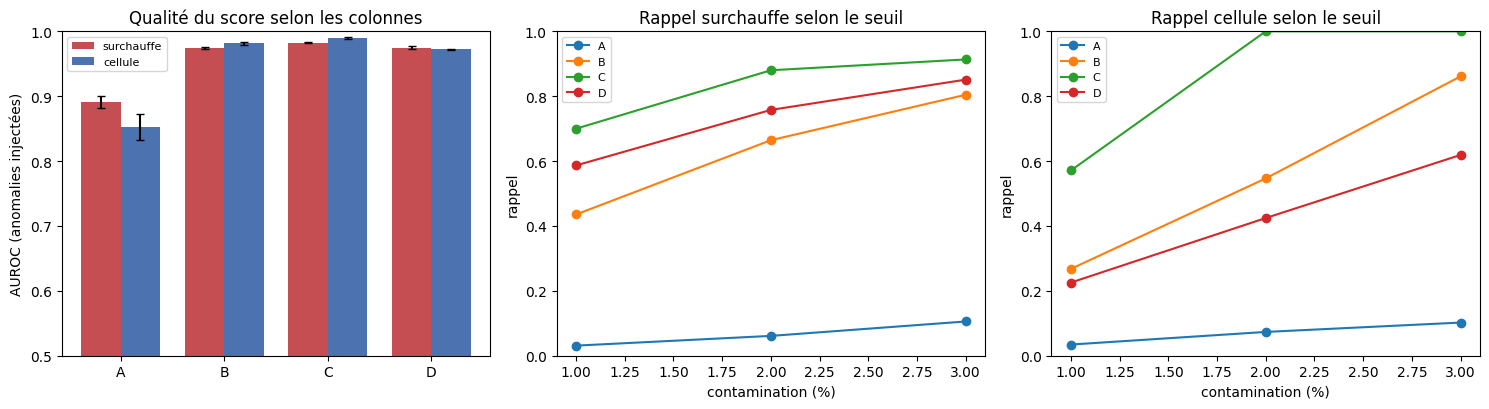

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# AUROC par configuration (moyenne ± écart-type sur 3 graines)
x = np.arange(len(CONFIGS))
for k, (t, couleur) in enumerate([("surchauffe", "#C44E52"), ("cellule", "#4C72B0")]):
    g = resultats.groupby("config")[f"auroc_{t}"]
    axes[0].bar(x + (k - 0.5) * 0.38, g.mean(), 0.38, yerr=g.std(), color=couleur, label=t, capsize=3)
axes[0].set_xticks(x, list(CONFIGS))
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel("AUROC (anomalies injectées)")
axes[0].set_title("Qualité du score selon les colonnes")
axes[0].legend(fontsize=8)

# Rappel selon la contamination
for ax, t in zip(axes[1:], ["surchauffe", "cellule"]):
    for nom in CONFIGS:
        ax.plot([c * 100 for c in CONTAMINATIONS],
                [tableau.loc[nom, f"rappel_{t}_{c:.0%}"] for c in CONTAMINATIONS], marker="o", label=nom)
    ax.set_xlabel("contamination (%)")
    ax.set_ylabel("rappel")
    ax.set_ylim(0, 1)
    ax.set_title(f"Rappel {t} selon le seuil")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "if_comparaison_configs.png", dpi=120)
plt.show()

### Vérification 2

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H2.1 | AUROC B − A ≥ 0,05 | B − A = **+0,106** ; A : rappel 6-7 % à 2 %, véhicule 9 au 15ᵉ rang | ✅ | Dilution massive : on ne donne **pas** toutes les colonnes au modèle |
| H2.2 | \|AUROC C − B\| ≤ 0,02 | C − B = +0,008 ; mais à 2 % : rappel surchauffe **88 %** (C) vs 66 % (B), cellule **100 %** vs 55 % ; véhicule 9 : 1ᵉʳ (C) vs 4ᵉ (B) | ✅ | L'AUROC résume tout le classement ; le rappel ne regarde que le **haut** du classement, là où l'on coupe — c'est là que C fait la différence. ⚠️ **Mais** l'injection cellule ne touche que `ecart_v_max` : une session injectée a un écart max haut et un écart moyen normal, combinaison irréaliste qui **désavantage B**. → vérifié en 2.1 |
| H2.3 | rappel cellule D − C ≥ 5 points | D − C = **−58 points** ; 25 % des votes de D sur des sessions courtes | ❌ | Isolation Forest coupe colonne par colonne, indépendamment : il ne sait pas raisonner « grand écart **sachant que** le SOC est bas ». Le SOC ne fait que diluer. → **SOC abandonné** ; le raisonnement « compte tenu du contexte » est le rôle du **modèle 1** (régression d'Ivan Jr) : les deux modèles sont complémentaires |
| H2.4 | moins de votes sur les sessions courtes sans elles à l'entraînement | 14,6 % (sans) vs 14,8 % (avec) ; variation entre graines : 13,5 à 15,8 % | ✅ sur le papier · ❌ en pratique | Différence **plus petite que la variation entre graines** → pas d'effet réel. Constat majeur : les sessions < 5 min font **1,1 %** des sessions mais **≈ 15 %** des votes (≈ 90 sur 621). → elles seront **« non évaluables »** (pas de vote) à l'étape 5 |
| H2.5 | gain 2 → 3 % < gain 1 → 2 % | 1 % : 63,6 % · 2 % : **94,0 %** · 3 % : 95,7 % (gains +30,4 puis +1,7 points) | ✅ | **2 % retenu** : passer à 3 % coûte ≈ 310 sessions de plus à vérifier pour +1,7 point |

## 2.1 Correction : une anomalie cellule réaliste

**Objectif :** vérifier que la supériorité de C sur B ne vient pas d'un **biais du banc d'essai**.

**Principe — la validité d'une évaluation dépend du réalisme des anomalies simulées.** Une anomalie injectée doit ressembler à une vraie panne ; sinon on mesure la capacité du modèle à repérer **notre façon de simuler**, pas la panne. Une vraie cellule défaillante fait monter **les deux** écarts (moyen et max). Injecter +60 mV sur le max seul crée une combinaison qui n'existe pas, et pénalise B (qui voit un écart moyen « normal »).

**Comment calibrer l'injection ? On utilise une vraie dégradation : celle du véhicule 9** (étape 1, H1.14). On compare ses sessions de **2019** (cellule saine) à ses sessions de **2021 au-dessus de 60 mV** (cellule dégradée) :

$$\text{ratio} = \frac{\Delta \text{ médiane}(\texttt{ecart\_v\_moyen})}{\Delta \text{ médiane}(\texttt{ecart\_v\_max})}$$

Injection réaliste : `ecart_v_max` + 60 mV **et** `ecart_v_moyen` + ratio × 60 mV.

| Calibrage possible | Pour nous |
|---|---|
| Ratio de médianes, véhicule 9 (2019 vs 2021 > 60 mV) | ✅ **retenu** : vient d'une vraie dégradation observée, médianes robustes |
| Pente de la régression moyen ~ max sur toutes les sessions | ⚠️ décrit la variation **normale** entre sessions, pas une dégradation → affichée pour comparaison |
| Même hausse (+60 mV) sur les deux écarts | ❌ un écart moyen qui monte autant que le max est physiquement peu probable (une seule cellule dérive, la moyenne est diluée) |

### Hypothèses (avant exécution)

| # | Hypothèse | Comment on la vérifie | Si elle est réfutée |
|---|---|---|---|
| **H2.6** | Avec l'injection réaliste, **C reste au moins aussi bonne que B** : rappel cellule à 2 % de C ≥ celui de B − 5 points | Rappel cellule à 2 %, injection réaliste | **On garde B** (les 4 features actuelles) : l'écart moyen apporte de l'information sur une vraie panne |
| **H2.7** | **Les autres conclusions tiennent** : C reste devant A et D en AUROC moyenne avec l'injection réaliste | AUROC moyenne | H2.1 / H2.3 seraient des artefacts du banc d'essai → les réexaminer |
| **H2.8** | Le ratio est **nettement inférieur à 1** (entre 0,2 et 0,8) : l'écart moyen monte moins que le max | Calcul du ratio | Si ≈ 1, toutes les cellules dérivent ensemble (vieillissement global, pas une cellule défaillante) ; si ≈ 0, l'écart moyen ne porte aucun signal de panne |

In [20]:
# Calibrage sur le véhicule 9 : cellule saine (2019) vs dégradée (2021, > 60 mV)
v9_sain = v9[v9["debut"].dt.year == 2019]
v9_degrade = v9[(v9["debut"].dt.year == 2021) & v9["haute"]]
delta = v9_degrade[["ecart_v_moyen", "ecart_v_max"]].median() - v9_sain[["ecart_v_moyen", "ecart_v_max"]].median()
ratio = delta["ecart_v_moyen"] / delta["ecart_v_max"]

display(pd.DataFrame({"2019 (sain)": v9_sain[["ecart_v_moyen", "ecart_v_max"]].median(),
                      "2021 > 60 mV (dégradé)": v9_degrade[["ecart_v_moyen", "ecart_v_max"]].median(),
                      "hausse": delta}).round(4))
print(f"{len(v9_sain)} sessions saines · {len(v9_degrade)} sessions dégradées")

# Pour comparaison : pente de la régression moyen ~ max sur toutes les sessions (variation normale)
pente = np.polyfit(Xv["ecart_v_max"], Xv["ecart_v_moyen"], 1)[0]
print(f"Ratio véhicule 9 = {ratio:.2f}   ·   pente moyen ~ max (toutes sessions) = {pente:.2f}")

verifier("H2.8", 0.2 <= ratio <= 0.8, f"ratio = {ratio:.2f} → injection : max + 60 mV, moyen + {ratio * 60:.0f} mV")

,2019 (sain),2021 > 60 mV (dégradé),hausse
ecart_v_moyen,0.0262,0.0374,0.0112
ecart_v_max,0.0330,0.0670,0.0340


302 sessions saines · 161 sessions dégradées
Ratio véhicule 9 = 0.33   ·   pente moyen ~ max (toutes sessions) = 0.71
H2.8 : CONFIRMÉE ✅   ratio = 0.33 → injection : max + 60 mV, moyen + 20 mV


In [21]:
def injecter_cellule_realiste(df):
    out = df.copy()
    out["ecart_v_max"] = out["ecart_v_max"] + 0.060
    out["ecart_v_moyen"] = out["ecart_v_moyen"] + ratio * 0.060
    return out

injectees_simples = injectees
injectees = {"surchauffe": injectees_simples["surchauffe"], "cellule": injecter_cellule_realiste(base)}
# Contrôle : la cohérence moyen ≤ max est conservée
assert (injectees["cellule"]["ecart_v_moyen"] <= injectees["cellule"]["ecart_v_max"]).all()

lignes = []
for nom, colonnes in CONFIGS.items():
    for graine in GRAINES:
        lignes.append({"config": nom, "graine": graine, **evaluer(colonnes, graine, train_fiable)})
resultats_realistes = pd.DataFrame(lignes)
resultats_realistes["auroc_moy"] = resultats_realistes[["auroc_surchauffe", "auroc_cellule"]].mean(axis=1)
tableau_realiste = resultats_realistes.groupby("config").mean(numeric_only=True)

comparaison_injection = pd.DataFrame({
    "AUROC cellule (simple)": tableau["auroc_cellule"],
    "AUROC cellule (réaliste)": tableau_realiste["auroc_cellule"],
    "rappel cellule 2 % (simple)": tableau["rappel_cellule_2%"],
    "rappel cellule 2 % (réaliste)": tableau_realiste["rappel_cellule_2%"],
    "AUROC moy. (réaliste)": tableau_realiste["auroc_moy"],
})
display(comparaison_injection.round(3))

,AUROC cellule (simple),AUROC cellule (réaliste),rappel cellule 2 % (simple),rappel cellule 2 % (réaliste),AUROC moy. (réaliste)
config,,,,,
A,0.852,0.916,0.073,0.114,0.903
B,0.981,0.996,0.547,0.993,0.985
C,0.989,0.989,1.000,1.000,0.986
D,0.973,0.973,0.424,0.424,0.974


In [22]:
# H2.6 — C face à B avec une panne réaliste
r_c, r_b = tableau_realiste.loc["C", "rappel_cellule_2%"], tableau_realiste.loc["B", "rappel_cellule_2%"]
verifier("H2.6", r_c >= r_b - 0.05, f"rappel cellule à 2 % (réaliste) : C = {r_c:.1%} · B = {r_b:.1%}")

# H2.7 — C devant A et D
a = tableau_realiste["auroc_moy"]
verifier("H2.7", a["C"] > a["A"] and a["C"] > a["D"],
         f"AUROC moy. (réaliste) : A = {a['A']:.3f} · B = {a['B']:.3f} · C = {a['C']:.3f} · D = {a['D']:.3f}")

H2.6 : CONFIRMÉE ✅   rappel cellule à 2 % (réaliste) : C = 100.0% · B = 99.3%
H2.7 : CONFIRMÉE ✅   AUROC moy. (réaliste) : A = 0.903 · B = 0.985 · C = 0.986 · D = 0.974


### Vérification 2.1

| # | Attendu | Observé | Verdict | Correction / conséquence |
|---|---|---|---|---|
| H2.6 | rappel cellule C ≥ B − 5 points (injection réaliste) | C = **100 %** · B = **99,3 %** (B était à 54,7 % avec l'injection simple) | ✅ | **Le biais suspecté existait** : l'injection simple pénalisait B. Sur la cellule, B et C sont à égalité |
| H2.7 | C devant A et D en AUROC moyenne | A = 0,903 · B = 0,985 · **C = 0,986** · D = 0,974 | ✅ | Les conclusions H2.1 (dilution) et H2.3 (abandon du SOC) tiennent |
| H2.8 | ratio entre 0,2 et 0,8 | **0,33** (écart max +34 mV, écart moyen +11 mV entre 2019 et 2021 > 60 mV) · pente sur toutes les sessions : 0,71 | ✅ | Signature d'**une cellule qui dérive seule** (la moyenne dilue son effet). Injection réaliste : max + 60 mV, moyen + 20 mV |

**Remarque pour l'étape 3 :** +60 mV est déjà une panne **franche** (le véhicule 9 dégradé n'a pris que +34 mV). Un rappel de 100 % sur une anomalie aussi grande ne dit rien des pannes **naissantes** → l'étape 3 testera des anomalies de plus en plus petites.

### Décision de l'étape 2 (validée par Stevy le 27/11/2026)

| Décision | Justification |
|---|---|
| **Colonnes : C = `temp_max`, `vitesse_temp`, `ecart_v_max`** | À égalité avec B sur la cellule (injection réaliste), mais **meilleure en surchauffe** (rappel 88 % contre 66 % à 2 % : l'écart moyen, inutile pour la surchauffe, dilue les coupures sur la température), **véhicule 9 au 1ᵉʳ rang** (contre 4ᵉ), et plus simple à expliquer : une colonne par aspect (niveau thermique, vitesse thermique, cellule) |
| **`contamination` = 2 %** | Rendements décroissants : +30 points de rappel de 1 à 2 %, +1,7 point de 2 à 3 % (H2.5) ; cohérent avec les ≈ 1,6 % signalés par les seuils |
| **Sessions < 5 min : exclues de l'entraînement, vote « non évaluable »** | Artefacts (étape 1) qui captent ≈ 15 % des votes pour 1,1 % des sessions (H2.4) |
| **Pas de SOC ni de colonnes de contexte** | Isolation Forest ne raisonne pas « sachant que » (H2.3) : le contexte est le rôle du modèle 1 |

À reporter dans `src/models/isolation_forest.py` à l'étape 5 (le code utilise encore les 4 colonnes de B).

> ✋ **Point de validation** : validé — étape 3.